# Citation verification

**Recipe 30** · Level 3 (Intermediate) · Decision type: `Choice`

Check each answer claim against its cited passage and flag unsupported or contradicted claims while Python verifies citation identifiers.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

An assistant's answer cites a passage for each claim it makes: a document id and a section number. Python checks the citation itself first, with no model involved: does that document and section actually exist? Only once a citation resolves to a real passage does Jev read the claim and the passage together and name one of three outcomes -- `supported`, `unsupported`, or `contradicted`. Python then composes the result: a citation that never resolved, or a claim the model calls `unsupported` or `contradicted` with enough [confidence](../../docs/glossary.md#confidence), is flagged for correction; a confidently `supported` claim is kept as cited; anything too uncertain goes to a person instead. By the end you will have seen both ways a claim can fail -- a citation that points nowhere, and a citation that points somewhere real but not to what the claim actually asserts -- and run an evaluation that scores the typed judgment itself and the composed, claim-level outcome it produces.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the 33 stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definition and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a number used to choose a setting on `validation`. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

In [1]:
from collections import Counter

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    per_class_metrics,
    select_confidence_threshold,
)
from jev_cookbook.fixtures import (
    load_inputs,
    load_labels,
    load_responses,
    responses_path,
    select_split,
)
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
questions = helpers.build_questions()
# N for the header is the number of examples the metrics are about: validation and test. This
# recipe has no train split; demo examples are shown but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result. This label does not depend on the run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

# A claim whose citation resolves needs at most one request; a claim whose citation does not
# resolve never asks one at all (helpers.resolve_citation runs first and is the only stage
# Python always applies). This cache makes sure a claim shown individually and later scored in
# its split is decided once, so the whole notebook makes exactly one request per resolved
# citation, never more.
answered = {}


def decide(example):
    if example.id not in answered:
        if helpers.resolve_citation(example.fields) is None:
            answered[example.id] = None
        else:
            state = helpers.build_state(example.fields)
            answered[example.id] = backend.decide(state, questions)["relation"]
    return answered[example.id]


print(f"stored answers available to replay: {len(load_responses())}{check}")
run_header(30, "Citation verification", backend=backend, n_examples=len(scored))

stored answers available to replay: 33 (a pipeline check, not a Jev result)
Recipe 30: Citation verification
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 38 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Python builds the state in two stages. First, `helpers.resolve_citation` looks up a claim's citation -- a document id and a section number -- in a small, fixed corpus of fabricated internal documentation (`helpers.CORPUS`); this never reaches Jev. Only when that lookup finds a real passage does `helpers.build_state` hand Jev the claim and that passage text, nothing else: the document id and section number stay in Python, attached to the outcome afterwards, so a result always traces back to the citation it came from.

In [2]:
demo = {e.id: e for e in examples if e.split == "demo"}
no_document = demo["demo-01-no-document"]
wrong_passage = demo["demo-02-wrong-passage"]

print("claim:", no_document.fields["claim"])
print("citation:", helpers.citation_label(no_document.fields))
print("resolves to:", helpers.resolve_citation(no_document.fields))
print()
print("claim:", wrong_passage.fields["claim"])
print("citation:", helpers.citation_label(wrong_passage.fields))
state = helpers.build_state(wrong_passage.fields)
print("Jev sees:", state)

claim: Backups of deleted files are kept for 90 days before being purged.
citation: BACKUP-POLICY§1
resolves to: None

claim: A refresh token stays valid for 30 days unless the account's password changes first.
citation: AUTH-TOKENS§1
Jev sees: {'claim': "A refresh token stays valid for 30 days unless the account's password changes first.", 'passage': 'Access tokens issued by the login endpoint expire 15 minutes after issue and cannot be renewed; a client must request a new token from the login endpoint once the old one expires.'}


The first claim cites `BACKUP-POLICY§1`; no document named `BACKUP-POLICY` exists in the corpus, so the citation resolves to nothing and Jev is never asked about it -- the same reasoning CONTRIBUTING.md section 3 gives for a `Choice` with no real options to offer: when there is nothing to weigh, the decision belongs to Python. The second claim cites a real passage, `AUTH-TOKENS§1`, but that passage is about how long an *access* token lasts, not a *refresh* token, which is what the claim actually asserts -- a real citation that is simply the wrong one for this claim. This is the second hard case this use case names: a correct claim can still be unsupported by its own citation.

## The questions

There is one question, and it asks one thing: given the claim and the passage its citation names, how does the passage relate to it? A `Choice` fits because the three outcomes are exclusive and Jev should commit to one. The option set is adapted from TypeSafe's citation-checking cookbook (S06): a `Choice` named `relation` with instructions "How does the section relate to the claim?" and three options, one of which is for a section that settles the claim neither way. This recipe widens that third option, renamed `unsupported`, into this use case's own fallback outcome (CONTRIBUTING.md section 3): it covers a passage that is simply off topic, one that only settles a narrower point, and -- the wrong-passage hard case above -- a real passage that is not the one that actually backs the claim.

A `Choice` answer's confidence is the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)`: 0 when the top outcome has no more than an even third of the three, 1 when one outcome holds all the probability.

In [3]:
relation = questions["relation"]
print(relation.instructions)
for name, description in relation.criteria.items():
    print(f"  {name:12s} {description}")

How does the passage relate to the claim?
  supported    The passage states the claim, or directly implies that it is true. A passage that states a strictly stronger fact also supports a weaker claim it logically contains.
  unsupported  The passage does not establish whether the claim is true or false. This covers a passage that is simply about a different topic, one that only settles a narrower or different point than the claim makes, and one that shares words with the claim without actually addressing what the claim asserts.
  contradicted The passage states the opposite of the claim, or gives a number, a date, or another concrete detail that is inconsistent with it.


## One answer up close

Before any aggregate, look at the two hard cases above answered in full. The first citation never resolved, so there is no question and no typed answer to show. The second shows the chosen outcome, a probability for every outcome, the confidence explained above, and a [provenance](../../docs/glossary.md#provenance) line -- here always `synthetic`, since nothing in this recipe's fixtures came from a real call.

In [4]:
print(f"citation {helpers.citation_label(no_document.fields)!r} does not resolve.")
print("No question is ever built for it, so there is no typed answer to show.")
assert decide(no_document) is None

citation 'BACKUP-POLICY§1' does not resolve.
No question is ever built for it, so there is no typed answer to show.


Choice: unsupported (confidence 0.60)
  unsupported   0.73  ###############
  supported     0.13  ###
  contradicted  0.13  ###
Provenance: synthetic


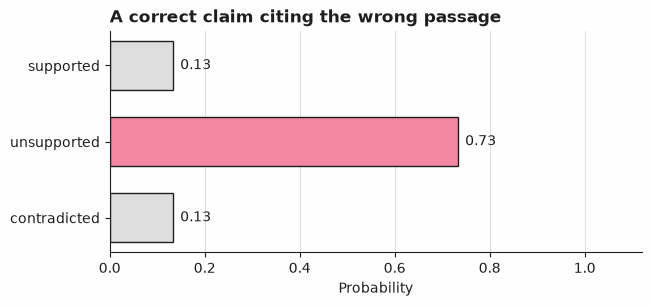

In [5]:
wrong_passage_answer = decide(wrong_passage)
show_answer(wrong_passage_answer)
plot_answer_probabilities(wrong_passage_answer, title="A correct claim citing the wrong passage")

The stored answer calls this `unsupported` at confidence 0.60: it correctly reads that `AUTH-TOKENS§1` says nothing about refresh tokens, whatever it says about access tokens. This is a demo claim, so nothing acts on it yet, but a less careful answer to the identical kind of claim -- confidently `supported`, because the claim sounds right in general -- is exactly what "Evaluation" finds, scored, below.

## Python's part

Jev supplies the judgment; what happens with it is code. `helpers.classify` is a two-stage rule. A citation that never resolved is flagged for correction directly, with no [confidence gate](../../docs/glossary.md#confidence-gate) and no [review](../../docs/glossary.md#review): nothing was asked, so there is nothing to be uncertain about. A citation that does resolve goes through the gate instead: below it, the claim is sent to review with the reason `"confidence below the threshold"`; at or above it, a confident `supported` claim is kept as cited, and a confident `unsupported` or `contradicted` claim is flagged for correction, the reason naming which.

The threshold itself is chosen here, on `validation`, and then frozen for the rest of this notebook. Only claims whose citation resolves have a confidence to choose it from -- a citation that never resolved was never asked a question, so it has none, and is left out of this selection entirely rather than given a stand-in value (CONTRIBUTING.md section 3; `docs/recipe-template.md` makes the same point for a case Python resolves on its own before any `Choice` is built). `helpers.resolved_subset` is that same filter, called here and by this recipe's own tests, so neither can apply a different one; `select_confidence_threshold` with `min_coverage=helpers.MIN_COVERAGE` (0.75) picks, among thresholds that would still answer at least three-quarters of those resolved claims, the one with the highest [accuracy](../../docs/glossary.md#accuracy).

In [6]:
val_examples = select_split(examples, "validation")
val_resolved = helpers.resolved_subset(val_examples)
val_resolved_answers = [decide(e) for e in val_resolved]
val_resolved_gold = [labels[e.id] for e in val_resolved]
val_resolved_correct = [
    a.choice == g for a, g in zip(val_resolved_answers, val_resolved_gold, strict=True)
]
val_resolved_confidence = [a.confidence for a in val_resolved_answers]
threshold = select_confidence_threshold(
    val_resolved_correct, val_resolved_confidence, min_coverage=helpers.MIN_COVERAGE
)
print(
    f"validation claims whose citation resolves: {len(val_resolved)} of "
    f"{len(val_examples)}{selection}{check}"
)
print(f"chosen threshold, frozen from here on: {threshold:.4f}{selection}{check}")

demo_actions, demo_queue = ActionLog(), ReviewQueue()
for shown_id, shown_example, shown_answer in (
    ("demo-01-no-document", no_document, decide(no_document)),
    ("demo-02-wrong-passage", wrong_passage, wrong_passage_answer),
):
    verdict = helpers.classify(
        shown_id,
        shown_example.fields,
        shown_answer,
        threshold,
        actions=demo_actions,
        queue=demo_queue,
    )
    print(
        f"{shown_id}: citation {helpers.citation_label(shown_example.fields)} "
        f"-> {verdict.verdict} ({verdict.action}) [{verdict.reason}]"
    )

validation claims whose citation resolves: 16 of 19 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen threshold, frozen from here on: 0.4500 (a selection step, not a reported result) (a pipeline check, not a Jev result)
demo-01-no-document: citation BACKUP-POLICY§1 -> unsupported (flagged for correction) [citation identifier does not resolve]
demo-02-wrong-passage: citation AUTH-TOKENS§1 -> unsupported (flagged for correction) [confident unsupported]


## Evaluation

The threshold was chosen and frozen above, on `validation`. This section reports what the frozen rule does, on every claim in each split -- the ones whose citation resolves and the ones that never asked a question at all. [Coverage](../../docs/glossary.md#coverage) is the fraction of claims `classify` actually decides, rather than sending to review; among those, accuracy is the fraction whose [gold label](../../docs/glossary.md#gold-label) -- the example's recorded correct answer, from `fixtures/labels.jsonl`, used only to score an answer after the fact and never shown to Jev -- the composed verdict matches, and [risk](../../docs/glossary.md#risk) is its complement. Because a citation that never resolved has no confidence gate to clear, `classify`'s own accept/review split -- not a plain confidence comparison -- decides what counts as answered here (`jev_cookbook.evaluation.evaluate_outcomes`, the [selective prediction](../../docs/glossary.md#selective-prediction) function for a rule with a review branch beyond the confidence gate).

Alongside that, `helpers.flag_agreement` scores a different, task-level question: not "did Jev name the right outcome" but "did the composed system end up correctly flagging this claim for correction or not", read off the TRUE gold label regardless of what Jev answered -- a claim sent to review counts as disagreement either way, since nobody decided. In an offline run every `test` number here is a check that the pipeline works, and it says so; every `validation` number, in every run mode, is also a selection step, which is why it carries both labels.

Three of the 19 claims in each split never reach a question at all: their citation does not resolve, so `classify` forces them to `unsupported`/flagged without asking Jev anything. Their gold label is always `unsupported` too, so they are correct by construction, at every threshold -- nothing about this fixture set could make them come out any other way. Reporting them alongside the claims Jev actually judged raises every composed number below; each code cell that reports a composed figure also reports the same figure over the resolved claims alone, so a reader can see what the model itself earned.

In [7]:
def decide_split(split_examples):
    actions, queue = ActionLog(), ReviewQueue()
    verdicts = [
        helpers.classify(e.id, e.fields, decide(e), threshold, actions=actions, queue=queue)
        for e in split_examples
    ]
    return verdicts, actions, queue


def split_metrics(split_examples, verdicts):
    gold = {e.id: labels[e.id] for e in split_examples}
    accepted, correct = helpers.accepted_and_correct(verdicts, gold)
    outcomes_result = evaluate_outcomes(accepted, correct)
    agreement = helpers.flag_agreement(verdicts, gold)
    return outcomes_result, agreement


def resolved_only_metrics(split_examples, verdicts):
    """The same two figures split_metrics reports, but excluding the forced, unresolved-
    citation claims entirely -- from the denominator as well as the numerator -- so this
    shows what the model's own judgment earns on its own, without the claims Python decided
    before ever asking a question."""
    gold = {e.id: labels[e.id] for e in split_examples}
    resolved_verdicts = [v for v in verdicts if v.citation_resolved]
    accepted, correct = helpers.accepted_and_correct(resolved_verdicts, gold)
    outcomes_result = evaluate_outcomes(accepted, correct)
    agreement = helpers.flag_agreement(resolved_verdicts, gold)
    return outcomes_result, agreement


def show_log(name, actions, queue):
    print(f"{name} action log: {len(actions)} entries{check}")
    for kind, n in sorted(Counter(e["kind"] for e in actions.to_dicts()).items()):
        print(f"  {kind:22s} {n}")
    print(f"{name} review queue: {len(queue)} entries{check}")
    for reason, n in sorted(Counter(i["reason"] for i in queue.to_dicts()).items()):
        print(f"  {reason:38s} {n}")


val_verdicts, val_actions, val_queue = decide_split(val_examples)
val_result, val_agreement = split_metrics(val_examples, val_verdicts)
val_resolved_result, val_resolved_agreement = resolved_only_metrics(val_examples, val_verdicts)
val_forced = [v for v in val_verdicts if not v.citation_resolved]
val_forced_correct = sum(v.verdict == labels[v.claim_id] for v in val_forced)

print(f"validation, {len(val_examples)} examples{selection}{check}")
print(
    f"accuracy of the raw choice, resolved citations only: "
    f"{accuracy(val_resolved_gold, val_resolved_answers):.4f}{selection}{check}"
)
print(
    f"forced (unresolved citation) claims: {val_forced_correct} of {len(val_forced)}, "
    f"correct by construction{selection}{check}"
)
print(
    f"answered (coverage): {val_result.n_answered} of {val_result.n_total} "
    f"(coverage {val_result.coverage:.4f}){selection}{check}"
)
print(
    f"accuracy among those answered: {val_result.accuracy:.4f} "
    f"(resolved claims only: {val_resolved_result.accuracy:.4f}){selection}{check}"
)
print(
    f"risk among those answered: {val_result.risk:.4f} "
    f"(resolved claims only: {val_resolved_result.risk:.4f}){selection}{check}"
)
print(
    f"flag/keep agreement with gold: {val_agreement:.4f} "
    f"(resolved claims only: {val_resolved_agreement:.4f}){selection}{check}"
)
show_log("validation", val_actions, val_queue)

validation, 19 examples (a selection step, not a reported result) (a pipeline check, not a Jev result)
accuracy of the raw choice, resolved citations only: 0.8750 (a selection step, not a reported result) (a pipeline check, not a Jev result)
forced (unresolved citation) claims: 3 of 3, correct by construction (a selection step, not a reported result) (a pipeline check, not a Jev result)
answered (coverage): 18 of 19 (coverage 0.9474) (a selection step, not a reported result) (a pipeline check, not a Jev result)
accuracy among those answered: 0.9444 (resolved claims only: 0.9333) (a selection step, not a reported result) (a pipeline check, not a Jev result)
risk among those answered: 0.0556 (resolved claims only: 0.0667) (a selection step, not a reported result) (a pipeline check, not a Jev result)
flag/keep agreement with gold: 0.8947 (resolved claims only: 0.8750) (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation action log: 18 entries (a pipeli

18 of the 19 validation claims clear `classify`'s own accept/review split -- the 16 whose citation resolves minus the one (`v-c5-wrong-low`) whose stored answer is too unconfident to act on, plus the 3 whose citation never resolved at all, forced through without ever asking a question. Those 3 are correct by construction: their gold label is always `unsupported`, exactly what the forced branch reports, so nothing about this fixture set could make them come out any other way, and they can only ever raise the composed figures below. Accuracy among the 18 answered claims is 0.9444; among the 15 *resolved* claims that answer, alone, it is 0.9333 -- one wrong either way, `v-u3-wrongpassage`, the wrong-passage hard case, confidently mislabelled `supported` even though the cited passage never addresses the refresh-token claim it is checked against. Flag/keep agreement (0.8947 composed, 0.8750 resolved-only) is lower still: it also counts the one claim sent to review as a disagreement, since the gate being cautious there still leaves nobody deciding whether that claim should have been flagged.

In [8]:
test_examples = select_split(examples, "test")
test_resolved = helpers.resolved_subset(test_examples)
test_resolved_answers = [decide(e) for e in test_resolved]
test_resolved_gold = [labels[e.id] for e in test_resolved]

test_verdicts, test_actions, test_queue = decide_split(test_examples)
test_result, test_agreement = split_metrics(test_examples, test_verdicts)
test_resolved_result, test_resolved_agreement = resolved_only_metrics(test_examples, test_verdicts)
test_forced = [v for v in test_verdicts if not v.citation_resolved]
test_forced_correct = sum(v.verdict == labels[v.claim_id] for v in test_forced)

print(f"test, {len(test_examples)} examples{check}")
print(
    f"accuracy of the raw choice, resolved citations only: "
    f"{accuracy(test_resolved_gold, test_resolved_answers):.4f}{check}"
)
print(
    f"forced (unresolved citation) claims: {test_forced_correct} of {len(test_forced)}, "
    f"correct by construction{check}"
)
print(
    f"answered (coverage): {test_result.n_answered} of {test_result.n_total} "
    f"(coverage {test_result.coverage:.4f}){check}"
)
print(
    f"accuracy among those answered: {test_result.accuracy:.4f} "
    f"(resolved claims only: {test_resolved_result.accuracy:.4f}){check}"
)
print(
    f"risk among those answered: {test_result.risk:.4f} "
    f"(resolved claims only: {test_resolved_result.risk:.4f}){check}"
)
# The resolved-only counts behind that resolved-only accuracy, printed rather than left to be
# divided back out of it: the discussion below names them.
test_resolved_answered = [
    e.id
    for e, a in zip(test_resolved, test_resolved_answers, strict=True)
    if a.confidence >= threshold
]
test_resolved_answered_wrong = [
    e.id
    for e, a, g in zip(test_resolved, test_resolved_answers, test_resolved_gold, strict=True)
    if a.confidence >= threshold and a.choice != g
]
print(
    f"resolved citations: {len(test_resolved_answered)} of {len(test_resolved)} answer, and "
    f"{len(test_resolved_answered_wrong)} of those are wrong "
    f"({', '.join(test_resolved_answered_wrong)}){check}"
)
print(
    f"flag/keep agreement with gold: {test_agreement:.4f} "
    f"(resolved claims only: {test_resolved_agreement:.4f}){check}"
)
show_log("test", test_actions, test_queue)
print(f"frozen gate from above: {threshold:.4f}{check}")

test, 19 examples (a pipeline check, not a Jev result)
accuracy of the raw choice, resolved citations only: 0.8750 (a pipeline check, not a Jev result)
forced (unresolved citation) claims: 3 of 3, correct by construction (a pipeline check, not a Jev result)
answered (coverage): 18 of 19 (coverage 0.9474) (a pipeline check, not a Jev result)
accuracy among those answered: 0.8889 (resolved claims only: 0.8667) (a pipeline check, not a Jev result)
risk among those answered: 0.1111 (resolved claims only: 0.1333) (a pipeline check, not a Jev result)
resolved citations: 15 of 16 answer, and 2 of those are wrong (t-c5-wrong, t-u3-wrongpassage) (a pipeline check, not a Jev result)
flag/keep agreement with gold: 0.8421 (resolved claims only: 0.8125) (a pipeline check, not a Jev result)
test action log: 18 entries (a pipeline check, not a Jev result)
  flagged for correction 10
  kept as cited          8
test review queue: 1 entries (a pipeline check, not a Jev result)
  confidence below the thr

Test confusion matrix (resolved citations only), gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->          supported   unsupported  contradicted (a pipeline check, not a Jev result)
  gold supported                6             0             0 (a pipeline check, not a Jev result)
  gold unsupported              1             4             0 (a pipeline check, not a Jev result)
  gold contradicted             1             0             4 (a pipeline check, not a Jev result)


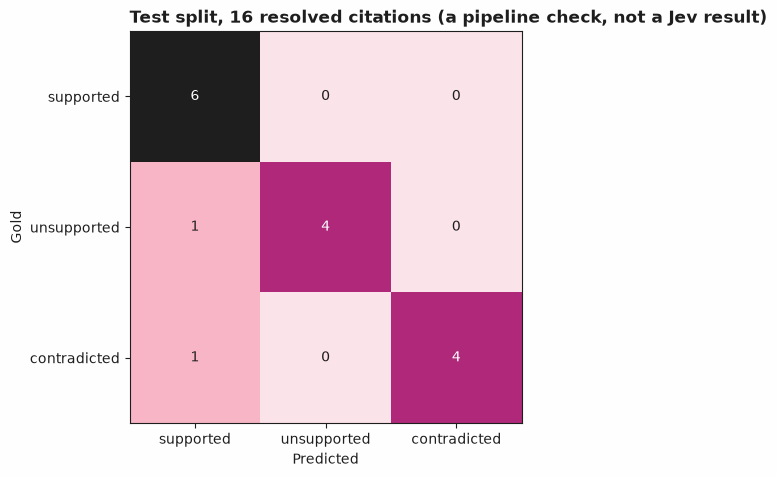

In [9]:
matrix = confusion_matrix(test_resolved_gold, test_resolved_answers, labels=list(helpers.OPTIONS))
width = max(len(label) for label in matrix.labels)
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(f"Test confusion matrix (resolved citations only), gold rows by predicted columns{check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{width}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, {len(test_resolved)} resolved citations{check}")

Test tells the same story with a real cost: 18 of 19 claims clear the split (the 16 resolved minus `t-u5-wrongpassage`, too unconfident to act on, plus the 3 unresolved citations, correct by construction as on `validation`), but 2 of the 15 claims that answer and whose citation resolves are wrong -- `t-c5-wrong` and `t-u3-wrongpassage`, both confidently `supported` above the frozen gate, both really claims a real passage does not back. Accuracy among the answered is 0.8889 composed, 0.8667 resolved-only; risk is 0.1111 composed, 0.1333 resolved-only -- a real, nonzero cost from this fixture set's own hard cases either way, not a guarantee the threshold buys. The confusion matrix below, over the 16 resolved citations alone, shows exactly where: row `unsupported`, column `supported` holds a 1, and row `contradicted`, column `supported` holds a 1 as well.

In [10]:
verdict_by_id = {v.claim_id: v for v in test_verdicts}
print(f"Test claims the raw choice got wrong, and what Python did with them{check}:")
for example, answer, gold in zip(
    test_resolved, test_resolved_answers, test_resolved_gold, strict=True
):
    if answer.choice != gold:
        verdict = verdict_by_id[example.id]
        print(
            f"  {example.id}: gold {gold}, answered {answer.choice} "
            f"(confidence {answer.confidence:.2f}) -> {verdict.verdict} [{verdict.reason}]"
        )

Test claims the raw choice got wrong, and what Python did with them (a pipeline check, not a Jev result):
  t-c5-wrong: gold contradicted, answered supported (confidence 0.52) -> supported [confident supported]
  t-u3-wrongpassage: gold unsupported, answered supported (confidence 0.60) -> supported [confident supported]


The cell above is why the rule is not enough on its own: a wrong answer with a high confidence passes the gate, and a real, correctly-worded claim can still be checked against the wrong passage. The fixtures include such cases on purpose, and a recipe's evaluation should find them rather than average them away.

## Claim-level evaluation

Everything above is still a question about the raw `Choice` judgment, scored only over the claims that reached Jev. The use case asks a wider question: across every claim, including the ones Python resolved entirely on its own, how well does the composed verdict -- the one `classify` actually reports -- identify the `unsupported` and `contradicted` claims that need flagging? [Precision](../../docs/glossary.md#precision), [recall](../../docs/glossary.md#recall), [F1](../../docs/glossary.md#f1) and [support](../../docs/glossary.md#support) answer that at claim level: a claim `classify` sends to review counts toward neither a class's predictions nor, for the three real outcomes, a correct one -- it only ever costs the recall of whichever class it would have been.

The 3 forced claims per split are always gold `unsupported` and always correctly flagged, so they only ever help `unsupported`'s recall, never `supported`'s or `contradicted`'s (neither class's rows are ever forced). Each row below prints the all-claims figure next to the same figure computed over the resolved claims alone, so this is visible rather than merely stated: `unsupported` recall/F1 is 0.8750/0.9333 all-claims against 0.8000/0.8889 resolved-only on `validation`, and 0.7500/0.8571 against 0.6000/0.7500 on `test` -- the use case's own headline number for this recipe, lower once the forced block is set aside.

In [11]:
val_gold_list = [labels[e.id] for e in val_examples]
test_gold_list = [labels[e.id] for e in test_examples]
val_final = [v.verdict for v in val_verdicts]
test_final = [v.verdict for v in test_verdicts]

val_resolved_v = [v for v in val_verdicts if v.citation_resolved]
test_resolved_v = [v for v in test_verdicts if v.citation_resolved]
val_resolved_final = [v.verdict for v in val_resolved_v]
val_resolved_gold_cl = [labels[v.claim_id] for v in val_resolved_v]
test_resolved_final = [v.verdict for v in test_resolved_v]
test_resolved_gold_cl = [labels[v.claim_id] for v in test_resolved_v]

for name, gold_list, final, resolved_gold_cl, resolved_final, lbl in (
    (
        "validation",
        val_gold_list,
        val_final,
        val_resolved_gold_cl,
        val_resolved_final,
        selection + check,
    ),
    ("test", test_gold_list, test_final, test_resolved_gold_cl, test_resolved_final, check),
):
    per_class = per_class_metrics(gold_list, final, labels=list(helpers.OPTIONS))
    per_class_resolved = per_class_metrics(
        resolved_gold_cl, resolved_final, labels=list(helpers.OPTIONS)
    )
    print(f"{name}, claim-level, {len(gold_list)} claims (resolved-only in parentheses){lbl}:")
    for option in helpers.OPTIONS:
        counts = per_class[option]
        resolved_counts = per_class_resolved[option]
        print(
            f"  {option:12s} precision {counts.precision:.4f} ({resolved_counts.precision:.4f})  "
            f"recall {counts.recall:.4f} ({resolved_counts.recall:.4f})  "
            f"f1 {counts.f1:.4f} ({resolved_counts.f1:.4f})  "
            f"support {counts.support} ({resolved_counts.support}){lbl}"
        )

# The lowest confidence on any gold-`supported` claim, across both splits: what the recall of
# 1.0000 above rests on, since a gold-`supported` claim below the frozen gate would be sent to
# review instead of kept. Printed because the discussion below names the number.
gold_supported_confidence = [
    decide(e).confidence
    for split_examples in (val_examples, test_examples)
    for e in helpers.resolved_subset(split_examples)
    if labels[e.id] == helpers.SUPPORTED
]
print(
    f"lowest confidence on any gold-supported claim, both splits: "
    f"{min(gold_supported_confidence):.2f}, against the frozen gate {threshold:.4f}{check}"
)

validation, claim-level, 19 claims (resolved-only in parentheses) (a selection step, not a reported result) (a pipeline check, not a Jev result):
  supported    precision 0.8571 (0.8571)  recall 1.0000 (1.0000)  f1 0.9231 (0.9231)  support 6 (6) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  unsupported  precision 1.0000 (1.0000)  recall 0.8750 (0.8000)  f1 0.9333 (0.8889)  support 8 (5) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  contradicted precision 1.0000 (1.0000)  recall 0.8000 (0.8000)  f1 0.8889 (0.8889)  support 5 (5) (a selection step, not a reported result) (a pipeline check, not a Jev result)
test, claim-level, 19 claims (resolved-only in parentheses) (a pipeline check, not a Jev result):
  supported    precision 0.7500 (0.7500)  recall 1.0000 (1.0000)  f1 0.8571 (0.8571)  support 6 (6) (a pipeline check, not a Jev result)
  unsupported  precision 1.0000 (1.0000)  recall 0.7500 (0.6000)  f1 0.8571 (0.750

On `test`, `unsupported` claims are caught less reliably (recall 0.7500, F1 0.8571 all-claims; 0.6000, 0.7500 resolved-only) than `contradicted` ones (recall 0.8000, F1 0.8889, identical either way -- no forced claim is ever gold `contradicted`): the wrong-passage hard case is the harder of this recipe's two failure modes to catch, because the claim itself reads as plausible and only the citation is wrong, and resolved-only, that gap between the two classes is wider, not narrower, than the all-claims figures alone would suggest. `validation` shows the same shape with fewer misses (`unsupported` recall 0.8750/0.8000, F1 0.9333/0.8889 all-claims/resolved-only; `contradicted` unchanged at 0.8000/0.8889), since only one wrong answer clears the frozen gate there (`v-u3-wrongpassage`). `supported` precision is 0.8571 on `validation` and 0.7500 on `test`, identical all-claims and resolved-only (no forced claim is ever gold `supported` either): nothing in this fixture set is ever wrongly flagged `unsupported` or `contradicted` when it is really `supported` -- both classes' precision is 1.0000 on both splits, all-claims and resolved-only alike -- so every mistake here runs the other way, a claim that should have been flagged, read as `supported` instead. `supported` recall is 1.0000 on both splits too: the lowest confidence on any gold-`supported` claim across both splits is 0.56, printed in the cell above and comfortably clear of the 0.4500 gate, so no gold-`supported` claim is ever sent to review instead of kept.

One baseline with no judgment about any passage at all: `helpers.trust_citation_baseline` trusts that a citation which resolves to a real document and section supports the claim, without ever reading what the passage actually says (and still calls an unresolved citation `unsupported`, the same forced call `classify` makes for it).

In [12]:
val_baseline = [helpers.trust_citation_baseline(e.fields) for e in val_examples]
test_baseline = [helpers.trust_citation_baseline(e.fields) for e in test_examples]
print(
    f"trust-citation baseline accuracy, validation: "
    f"{accuracy(val_gold_list, val_baseline):.4f}{selection}{check}"
)
print(
    f"trust-citation baseline accuracy, test: {accuracy(test_gold_list, test_baseline):.4f}{check}"
)
print(
    f"raw choice accuracy among resolved citations, test (for comparison): "
    f"{accuracy(test_resolved_gold, test_resolved_answers):.4f}{check}"
)

trust-citation baseline accuracy, validation: 0.4737 (a selection step, not a reported result) (a pipeline check, not a Jev result)
trust-citation baseline accuracy, test: 0.4737 (a pipeline check, not a Jev result)
raw choice accuracy among resolved citations, test (for comparison): 0.8750 (a pipeline check, not a Jev result)


The raw choice beats this baseline by a wide margin on both splits (0.4737 for the baseline against 0.8750 for the choice among resolved citations): simply trusting that a real citation backs its claim is wrong on every `unsupported` and `contradicted` claim in this fixture set, resolved or not. Both splits' baseline accuracy land on the same number because this fixture set gives each split the same mix of outcomes (6 `supported`, 5 `contradicted`, 5 `unsupported`, 3 unresolved) -- a property of how this recipe's fixtures were built, not a claim about how Jev performs.

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. `N` below counts only the claims that carry a gold label -- every `validation` and `test` example -- so it excludes the two `demo` claims shown earlier.

In [13]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 19 validation and 19 test examples (a pipeline check, not a Jev result)


## Next steps

- Add a hard claim to `ROWS` in `build_fixtures.py` -- a citation that resolves to a passage settling only part of a multi-part claim, say -- run `python build_fixtures.py`, and see where `classify` sends it.
- In `helpers.py`, change `MIN_COVERAGE` from `0.75` to a higher value and see which claims the gate stops answering first: every figure in "Evaluation" above is computed from the frozen threshold that constant produces, so all of them move together, not only the ones that look like they should.
- Compare the action log between `validation` and `test` above: both split 18 accepted claims differently between kept and flagged, and only `test`'s flagged count includes a confidently wrong `supported` answer.
- Neighbouring recipes: [`20-claim-support-classification`](../20-claim-support-classification/) (`Choice`) asks the closest single question on its own, without the citation-identifier stage this recipe adds in front of it; [`29-tool-outcome-verification`](../29-tool-outcome-verification/) (`Choice`) composes the same confidence-gate-then-action pattern over a different kind of evidence.